# B22 怎样从一批笔记中找到相关段落？

任务：将中文手册切成带来源片段，用 TF-IDF 检索，并用预先标注的问题检查 Recall@k 和 MRR。

先修：B08、B20；切片、稀疏矩阵和排名。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 文档与人工相关性标签
内容是虚构校园规则；字典键为来源 ID。评测问题提前指定相关文档，不让检索器自己给自己标答案。

In [2]:
import json
import time
import numpy as np
started = time.perf_counter()
def finish(metrics):
    metrics["elapsed_seconds"] = round(time.perf_counter() - started, 3)
    (OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2))
def barplot(labels, values, title, filename="comparison.png"):
    fig, ax = plt.subplots()
    ax.bar(labels, values)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename)
    plt.close(fig)

from sklearn.feature_extraction.text import TfidfVectorizer
documents = {'D1': '实验室预约需要提前一天提交申请。每次预约最长两小时。取消预约请在开始前四小时通知管理员。管理员会检查设备使用资格。', 'D2': '图书馆工作日晚上22点关闭。周末晚上20点关闭。借书期限为30天，续借需要通过图书管理系统办理。', 'D3': '校园开放日的签到地点是一号楼大厅。志愿者早上8点集合。访客请携带报名二维码。活动遇到大雨时转入体育馆。', 'D4': '共享单车故障时请停止骑行并上报车辆编号。不能把车停在消防通道。每周维护人员会检查刹车和轮胎。', 'D5': '报销材料包括发票、支付凭证和项目编号。财务在每周五处理申请。交通费与餐费应分别填写。', 'D6': '服务器训练任务最长运行六小时。提交前需要记录随机种子和依赖版本。GPU预约冲突时优先安排已批准的课程实验。'}
queries = [('实验室预约最长多久', 'D1'), ('周末图书馆几点关闭', 'D2'), ('下大雨开放日去哪里', 'D3'), ('共享单车故障需要报告什么', 'D4'), ('报销需要哪些材料', 'D5'), ('训练任务最长多长时间', 'D6')]
(DATA_DIR / 'notes.json').write_text(json.dumps(documents, ensure_ascii=False, indent=2), encoding='utf-8')

371

## 2. 切分保留来源与字符位置
采用 40 字窗口和 10 字重叠，使这些短手册也实际产生多个片段。保存 start/end，使片段可以回查；真实长文可改用句子边界，防止割裂条件。

In [3]:
def chunk_text(text, width=40, overlap=10):
    if not 0 <= overlap < width:
        raise ValueError('要求 0 <= overlap < width')
    result = []
    for start in range(0, len(text), width - overlap):
        result.append((start, min(start + width, len(text)), text[start:start + width]))
        if start + width >= len(text):
            break
    return result
chunks = []
for doc_id, text in documents.items():
    for start, end, part in chunk_text(text):
        chunks.append({'doc_id': doc_id, 'start': start, 'end': end, 'text': part})
assert all((documents[c['doc_id']][c['start']:c['end']] == c['text'] for c in chunks))
assert len(chunks) > len(documents)

## 3. 字符 n-gram 关键词索引
中文无空格，因此用字符 2—4 gram，不依赖外部分词器。规范化 TF-IDF 的点积等于余弦相似度；零匹配和空查询不能返回假命中。

In [4]:
vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 4))
matrix = vectorizer.fit_transform([c['text'] for c in chunks])

def retrieve(query, k=3):
    if not query.strip():
        return []
    scores = (matrix @ vectorizer.transform([query]).T).toarray().ravel()
    order = np.argsort(-scores, kind='stable')[:k]
    return [{**chunks[i], 'score': float(scores[i])} for i in order if scores[i] > 0]
print(retrieve(queries[0][0]))

[{'doc_id': 'D1', 'start': 0, 'end': 40, 'text': '实验室预约需要提前一天提交申请。每次预约最长两小时。取消预约请在开始前四小时通知', 'score': 0.37936034177912303}, {'doc_id': 'D6', 'start': 30, 'end': 53, 'text': '本。GPU预约冲突时优先安排已批准的课程实验。', 'score': 0.048452088425244025}, {'doc_id': 'D6', 'start': 0, 'end': 40, 'text': '服务器训练任务最长运行六小时。提交前需要记录随机种子和依赖版本。GPU预约冲突时', 'score': 0.03538279605858653}]


## 4. 排名评价与失败记录
Recall@k 判断正确来源是否进入前 k；MRR 是首个相关结果名次倒数。这里按来源判断相关，不意味着每个命中片段都已包含答案。

In [5]:
results = []
for query, gold in queries:
    hits = retrieve(query, 3)
    ranks = [i + 1 for i, h in enumerate(hits) if h['doc_id'] == gold]
    results.append({'query': query, 'gold': gold, 'hits': hits, 'hit1': bool(hits and hits[0]['doc_id'] == gold), 'hit3': bool(ranks), 'rr': 1 / min(ranks) if ranks else 0.0})
(OUT_DIR / 'retrieval_results.json').write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding='utf-8')
scores = [float(np.mean([r['hit1'] for r in results])), float(np.mean([r['hit3'] for r in results])), float(np.mean([r['rr'] for r in results]))]
barplot(['Recall@1', 'Recall@3', 'MRR@3'], scores, '人工标注问题的检索表现')
finish({'recall_at_1': scores[0], 'recall_at_3': scores[1], 'mrr_at_3': scores[2], 'chunks': len(chunks), 'evaluation_questions': len(queries)})

{
  "recall_at_1": 1.0,
  "recall_at_3": 1.0,
  "mrr_at_3": 1.0,
  "chunks": 12,
  "evaluation_questions": 6,
  "elapsed_seconds": 0.829
}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

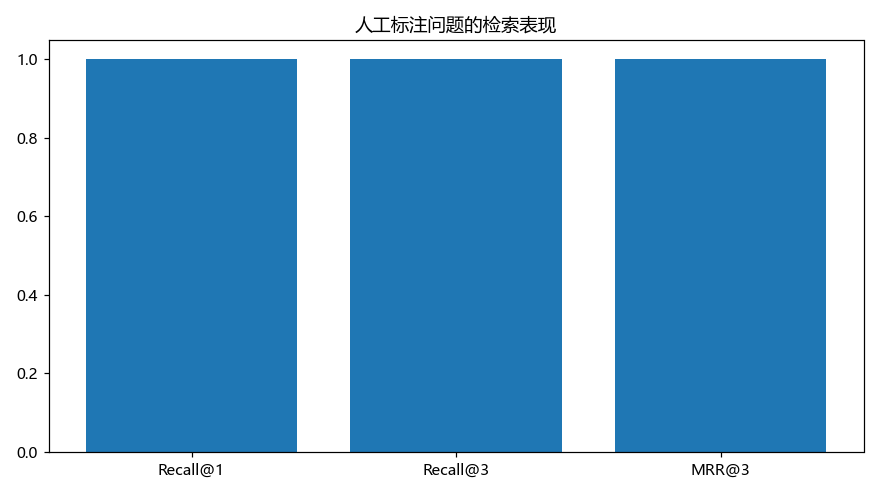

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
虚构规则不是实际学校规定；命中来源不等于正确回答。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。